# 01 — Data validation | Lichess clock increment study

**Research question:** Among comparable rated Lichess games with the same starting clock, how is a positive per-move increment associated with a player's probability of losing on time? Later notebooks will examine the assumptions required for causal interpretation.

**Unit of analysis:** Player-game observation (two per game). **Treatment:** `has_increment`. **Outcome:** `lost_on_time`.

This notebook validates data exported by `src/prepare_increment_data.py`. It **does not estimate a causal effect**.

## 1. Load both datasets

Run this notebook from VS Code with the project virtual environment selected as the kernel. Expected paths are `data/processed/increment_games.csv` and `data/processed/increment_player_games.csv`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resolve project root when launched from either repository root or notebooks/.
location = Path.cwd()
ROOT = next((p for p in [location, *location.parents] if (p / "data" / "processed").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Expected data/processed/ at the project root. Copy the two CSVs there.")

DATA = ROOT / "data" / "processed"
games = pd.read_csv(DATA / "increment_games.csv", parse_dates=["started_at_utc"])
pg = pd.read_csv(DATA / "increment_player_games.csv", parse_dates=["started_at_utc"])
print("Project root:", ROOT)
print("Games:", games.shape, "Player-games:", pg.shape)
display(pg.head())

Project root: c:\Users\jenny\Projects\lichess-increment-causal-inference
Games: (112440, 16) Player-games: (224880, 20)


,game_id,started_at_utc,event,result,termination,initial_seconds,increment_seconds,has_increment,time_control,common_support_base,player,opponent,player_elo,opponent_elo,color,elo_diff,lost,won,draw,lost_on_time
0,j1dkb5dw,2012-12-31 23:01:03+00:00,Rated Classical game,1-0,Normal,600,8,1,600+8,1,BFG9k,mamalak,1639,1403,white,236,0,1,0,0
1,a9tcp02g,2012-12-31 23:04:12+00:00,Rated Classical game,1-0,Normal,480,2,1,480+2,1,Desmond_Wilson,savinka59,1654,1919,white,-265,0,1,0,0
2,szom2tog,2012-12-31 23:03:15+00:00,Rated Classical game,1-0,Normal,420,17,1,420+17,1,Kozakmamay007,VanillaShamanilla,1643,1747,white,-104,0,1,0,0
3,rklpc7mk,2012-12-31 23:04:57+00:00,Rated Bullet game,0-1,Normal,60,1,1,60+1,1,Naitero_Nagasaki,800,1824,1973,white,-149,1,0,0,0
4,1xb3os63,2012-12-31 23:02:37+00:00,Rated Bullet game,0-1,Normal,60,1,1,60+1,1,nichiren1967,Naitero_Nagasaki,1765,1815,white,-50,1,0,0,0


## 2. Column types and missingness

Check types, missing values, and values that may be invalid even if they are not null.

In [2]:
print("Game-level columns:", games.columns.tolist())
print("Player-level columns:", pg.columns.tolist())
display(pd.DataFrame({"dtype": pg.dtypes.astype(str), "missing": pg.isna().sum(), "missing_pct": pg.isna().mean().mul(100).round(2)}))
display(pg[["player_elo", "opponent_elo", "initial_seconds", "increment_seconds"]].describe())

Game-level columns: ['game_id', 'date_utc', 'time_utc', 'event', 'white', 'black', 'white_elo', 'black_elo', 'result', 'termination', 'initial_seconds', 'increment_seconds', 'has_increment', 'time_control', 'started_at_utc', 'common_support_base']
Player-level columns: ['game_id', 'started_at_utc', 'event', 'result', 'termination', 'initial_seconds', 'increment_seconds', 'has_increment', 'time_control', 'common_support_base', 'player', 'opponent', 'player_elo', 'opponent_elo', 'color', 'elo_diff', 'lost', 'won', 'draw', 'lost_on_time']


,dtype,missing,missing_pct
game_id,str,0,0.0
started_at_utc,"datetime64[us, UTC]",0,0.0
event,str,0,0.0
result,str,0,0.0
termination,str,0,0.0
initial_seconds,int64,0,0.0
increment_seconds,int64,0,0.0
has_increment,int64,0,0.0
time_control,str,0,0.0
common_support_base,int64,0,0.0


,player_elo,opponent_elo,initial_seconds,increment_seconds
count,224880.000000,224880.000000,224880.000000,224880.000000
mean,1599.184841,1599.184841,321.998399,3.000471
std,207.148249,207.148249,284.603950,4.470174
min,789.000000,789.000000,60.000000,0.000000
25%,1464.000000,1464.000000,120.000000,0.000000
50%,1592.000000,1592.000000,300.000000,1.000000
75%,1736.000000,1736.000000,360.000000,5.000000
max,2403.000000,2403.000000,1800.000000,30.000000


In [3]:
required_games = {"game_id", "white", "black", "result", "termination", "initial_seconds", "increment_seconds", "has_increment", "started_at_utc", "common_support_base"}
required_pg = {"game_id", "player", "opponent", "color", "player_elo", "opponent_elo", "elo_diff", "initial_seconds", "increment_seconds", "has_increment", "lost", "won", "draw", "lost_on_time", "termination", "result", "common_support_base"}
assert required_games <= set(games.columns), required_games - set(games.columns)
assert required_pg <= set(pg.columns), required_pg - set(pg.columns)
assert games["game_id"].notna().all() and pg["game_id"].notna().all()
assert games["started_at_utc"].notna().all() and pg["started_at_utc"].notna().all()
assert (pg[["initial_seconds", "player_elo", "opponent_elo"]] > 0).all().all()
assert (pg["increment_seconds"] >= 0).all()
print("✓ Required columns, dates, and numeric ranges pass")

✓ Required columns, dates, and numeric ranges pass


## 3. Unique identifiers and two-sided game expansion

Each game appears once in `games`, and exactly twice in `pg`: one White observation and one Black observation.

In [4]:
assert games["game_id"].is_unique, "Duplicate game IDs in game-level data"
per_game = pg.groupby("game_id", sort=False).agg(n_rows=("player", "size"), n_colors=("color", "nunique"), n_treatments=("has_increment", "nunique"))
assert len(per_game) == len(games)
assert per_game["n_rows"].eq(2).all()
assert per_game["n_colors"].eq(2).all()
assert per_game["n_treatments"].eq(1).all()
assert set(pg["game_id"]) == set(games["game_id"])
assert set(pg["color"].unique()) == {"white", "black"}
assert pg.groupby("game_id")["player"].nunique().eq(2).all()
print(f"✓ {len(games):,} unique games map to {len(pg):,} player-game rows")

✓ 112,440 unique games map to 224,880 player-game rows


## 4. Verify treatment encoding

`has_increment = 1` means `increment_seconds > 0`. A game assigns the *same* time control to both players.

In [5]:
for frame in [games, pg]:
    assert frame["has_increment"].isin([0, 1]).all()
    assert frame["has_increment"].eq(frame["increment_seconds"].gt(0).astype(int)).all()
    assert frame["common_support_base"].isin([0, 1]).all()
print("✓ Treatment flags match increments")
display(games.groupby("has_increment").agg(games=("game_id", "size"), starting_clocks=("initial_seconds", "nunique"), median_start_seconds=("initial_seconds", "median")))

✓ Treatment flags match increments


,games,starting_clocks,median_start_seconds
has_increment,,,
0,54573,27,180.0
1,57867,30,300.0


## 5. Verify outcome coding, including unusual time-forfeit draws

`Termination = Time forfeit` describes a **game**, not necessarily a loss for each player. Our primary outcome is 1 **only** for the losing side of a decisive game terminated by time forfeit. Lichess can record time-forfeit draws; neither player has a `lost_on_time` event in such games.

This measures the **probability of losing a game on time**, not the probability that anyone's clock expires.

In [6]:
assert pg[["lost", "won", "draw", "lost_on_time"]].isin([0,1]).all().all()
assert pg[["lost", "won", "draw"]].sum(axis=1).eq(1).all()
assert pg["lost_on_time"].eq(((pg["termination"] == "Time forfeit") & (pg["lost"] == 1)).astype(int)).all()
assert (pg["lost_on_time"] <= pg["lost"]).all()
assert games["result"].isin(["1-0", "0-1", "1/2-1/2"]).all()
assert games["termination"].isin(["Normal", "Time forfeit"]).all()

termination_by_result = pd.crosstab(games["termination"], games["result"], margins=True)
display(termination_by_result)
forfeit_draws = games.query("termination == 'Time forfeit' and result == '1/2-1/2'")
print(f"Time-forfeit draws (neither player lost): {len(forfeit_draws):,}")
assert pg.groupby("game_id")["lost_on_time"].sum().le(1).all()
assert pg["lost_on_time"].sum() == len(games.query("termination == 'Time forfeit' and result != '1/2-1/2'"))
print("✓ Outcome is consistent with result and termination")

result,0-1,1-0,1/2-1/2,All
termination,,,,
Normal,36130,40292,3243,79665
Time forfeit,15146,17113,516,32775
All,51276,57405,3759,112440


Time-forfeit draws (neither player lost): 516
✓ Outcome is consistent with result and termination


In [12]:
# Validate the total number of decisive time-forfeit losses

decisive_time_forfeits = games.loc[
    (games["termination"] == "Time forfeit")
    & (games["result"].isin(["1-0", "0-1"]))
]

recorded_timeout_losses = pg["lost_on_time"].sum()

assert len(decisive_time_forfeits) == recorded_timeout_losses

print("Decisive time forfeits:", len(decisive_time_forfeits))
print("Recorded timeout losses:", recorded_timeout_losses)

Decisive time forfeits: 32259
Recorded timeout losses: 32259


## 6. Compare increment and non-increment observations (descriptive only)

These are *unadjusted associations*. Differences should not be called causal effects.

,observations,games,timeout_loss_rate,mean_player_elo,mean_opponent_elo,median_initial_seconds,timeout_loss_pct
has_increment,,,,,,,
0,109146,54573,0.19,1640.14,1640.14,180.0,18.81
1,115734,57867,0.10,1560.56,1560.56,300.0,10.13


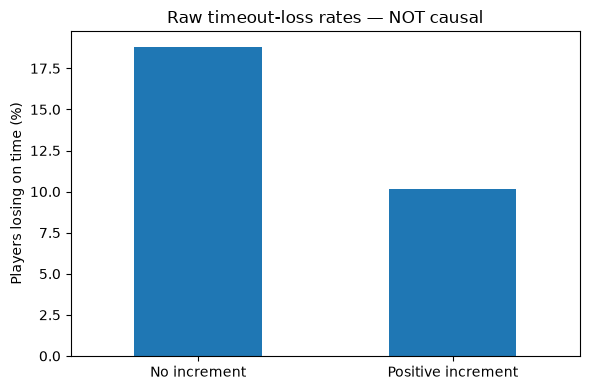

In [7]:
raw = pg.groupby("has_increment").agg(
    observations=("lost_on_time", "size"),
    games=("game_id", "nunique"),
    timeout_loss_rate=("lost_on_time", "mean"),
    mean_player_elo=("player_elo", "mean"),
    mean_opponent_elo=("opponent_elo", "mean"),
    median_initial_seconds=("initial_seconds", "median"),
)
display(raw.assign(timeout_loss_pct=lambda d: d["timeout_loss_rate"]*100).round(2))
fig, ax = plt.subplots(figsize=(6,4))
raw["timeout_loss_rate"].mul(100).plot.bar(ax=ax)
ax.set_xticklabels(["No increment", "Positive increment"], rotation=0)
ax.set_ylabel("Players losing on time (%)")
ax.set_xlabel("")
ax.set_title("Raw timeout-loss rates — NOT causal")
plt.tight_layout()
plt.show()

### Preliminary Confounding Assessment

The unadjusted timeout-loss rate is approximately 18.81% for games
without increments and 10.13% for games with increments, representing
an 8.68 percentage-point difference.

However, this difference should not be interpreted as causal because
the treatment and control groups differ in important characteristics.

**Potential confounders:**

- **Starting clock duration:** Games with increments tend to have
  longer initial time controls. Starting clock duration may influence
  both increment selection and the probability of losing on time.

- **Player rating:** Players in non-increment games have higher
  average Elo ratings. Rating may be associated with time-control
  preferences and time-management ability.

**Implications for causal identification:**

Future analyses should compare games with identical starting clocks
and adjust for player and opponent ratings.

Where feasible, within-player comparisons may help control for
time-invariant player characteristics.

The observed 8.68 percentage-point difference represents an
unadjusted association, not an identified causal effect.

## 7. Starting-clock overlap

Compare games with the **same initial seconds**. This is necessary, but insufficient, for causal identification. A starting-clock duration is on support when both treatment categories appear. Examine group sizes too: a clock with 1 treated game and 1 untreated game technically overlaps but is weak evidence.

In [8]:
clock_counts = games.groupby(["initial_seconds", "has_increment"]).size().unstack(fill_value=0).reindex(columns=[0,1], fill_value=0)
clock_counts.columns = ["no_increment_games", "increment_games"]
clock_counts["both_present"] = clock_counts[["no_increment_games", "increment_games"]].gt(0).all(axis=1)
clock_counts["min_arm_size"] = clock_counts[["no_increment_games", "increment_games"]].min(axis=1)
clock_counts["total_games"] = clock_counts["no_increment_games"] + clock_counts["increment_games"]
display(clock_counts.sort_values("total_games", ascending=False).head(20))
print("Games at starting clocks with both groups:", int(games["common_support_base"].sum()))
print("Games outside starting-clock overlap:", int((games["common_support_base"] == 0).sum()))
assert games["common_support_base"].eq(games["initial_seconds"].map(clock_counts["both_present"]).astype(int)).all()

,no_increment_games,increment_games,both_present,min_arm_size,total_games
initial_seconds,,,,,
300,10172,18626,True,10172,28798
60,14523,6343,True,6343,20866
180,8243,6985,True,6985,15228
120,5950,3172,True,3172,9122
240,3850,3064,True,3064,6914
600,2448,4242,True,2448,6690
420,1693,3495,True,1693,5188
480,1786,3195,True,1786,4981
900,1878,2085,True,1878,3963


Games at starting clocks with both groups: 112393
Games outside starting-clock overlap: 47


## 8. Within-player treatment variation

If we later use player fixed effects, only players observed under both increment conditions contribute directly to identifying a treatment coefficient. The same players may still face different opponents or choose time controls for different reasons.

In [9]:
eligible = pg.loc[pg["common_support_base"] == 1].copy()
switcher_mask = eligible.groupby("player")["has_increment"].nunique().eq(2)
switchers = switcher_mask[switcher_mask].index
print("Unique players in overlap cohort:", eligible["player"].nunique())
print("Players seen with both increment statuses:", len(switchers))
print("Player-game rows for these players:", eligible["player"].isin(switchers).sum())

# Stricter: variation for the SAME player and SAME starting clock.
within_player_clock = eligible.groupby(["player", "initial_seconds"])["has_increment"].nunique().eq(2)
print("Player × starting-clock strata with both statuses:", int(within_player_clock.sum()))

Unique players in overlap cohort: 4823
Players seen with both increment statuses: 2713
Player-game rows for these players: 199776
Player × starting-clock strata with both statuses: 6940


## 9. Explicit pre-modeling decisions

- **Primary unit:** player-game; two observations from one game are statistically dependent.
- **Treatment:** any positive increment versus none, conditional on the starting clock. Different positive increments remain grouped; consider a specific policy (e.g. `300+5` vs `300+0`) as a sensitivity analysis.
- **Outcome:** losing on time, defined by `Termination == Time forfeit` *and* a decisive loss.
- **Main candidate cohort:** `common_support_base == 1`, subject to stronger overlap and minimum sample sizes.
- **Potential pre-game covariates:** player rating, opponent rating, player identity, color, starting clock, UTC start time (interpret cautiously).
- **Avoid adjusting for:** number of moves, game length, termination reason, end-of-game rating change, or opening reached during the game: these occur after treatment assignment or define the outcome.
- **Uncertainty:** the same two players appear in many games, and two observations share one game; naive independent-row standard errors are inappropriate.
- **Unobserved confounding:** players self-select time controls. Good overlap and regression adjustment alone cannot prove causality.

**Next notebook:** `02_exploratory_analysis.ipynb` — visualize covariate balance and investigate robust comparable cohorts. No model-fitting needed yet.